# Retail Decision Intelligence — V3 Expiry Recalibration Audit

**Purpose:** Inspect and validate `documentation/expiry_recalibration_audit.csv` in Dataset V3, then cross-check it against `historical/sales_daily.csv`, `historical/wastage.csv`, `master/stores.csv`, and `master/products.csv`.

This notebook is designed for the actual V3 folder structure and column names.

### What this notebook checks
1. Dataset paths, required files, columns, row counts, and duplicate keys.
2. V2 versus V3 expired-unit totals and the recalibration rule.
3. Expiry cap and available-stock guardrails.
4. Agreement between the audit file and daily sales records.
5. Agreement between daily sales expiry and the wastage ledger.
6. Wastage cost calculation using product cost.
7. Store, city, category, SKU, and date-level summaries.
8. Exportable validation reports and audit extracts.

**Important interpretation:** V3's lower expiry is a synthetic dataset recalibration, not an AI-generated business improvement or a real-world benchmark. The configured 5% cap is a modeling assumption. V3 does not yet implement full FIFO batch-age simulation, and purchase orders/goods receipts retain their V2 records.

## 1. Imports and configuration

If you extracted the ZIP file, the folder should be named `retail_decision_intelligence_v3` and contain `documentation`, `historical`, and `master` folders.

The code first tries common locations. If it cannot find the folder, set `DATA_DIR` manually.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Edit this only if your extracted dataset is stored elsewhere.
CANDIDATE_DIRS = [
    Path("retail_decision_intelligence_v3"),
    Path("data/retail_decision_intelligence_v3"),
    Path("/mnt/data/retail_decision_intelligence_v3"),
    Path.cwd() / "retail_decision_intelligence_v3",
]

DATA_DIR = next((p.resolve() for p in CANDIDATE_DIRS if p.exists()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find 'retail_decision_intelligence_v3'. "
        "Set DATA_DIR = Path(r'FULL/PATH/TO/retail_decision_intelligence_v3')."
    )

print("Dataset folder:", DATA_DIR)

Dataset folder: D:\TCS AI\retail_decision_intelligence_v3


## 2. Load the exact V3 files

The V3 schema uses:
- Store city field: `location` (not `city`)
- Product perishability field: `is_perishable` (not `perishable`)
- Sales expiry field: `expired_units`
- Wastage date field: `date`

In [2]:
FILES = {
    "audit": DATA_DIR / "documentation" / "expiry_recalibration_audit.csv",
    "config": DATA_DIR / "documentation" / "v3_recalibration_config.json",
    "quality_report": DATA_DIR / "documentation" / "data_quality_report_v3.json",
    "sales": DATA_DIR / "historical" / "sales_daily.csv",
    "wastage": DATA_DIR / "historical" / "wastage.csv",
    "stores": DATA_DIR / "master" / "stores.csv",
    "products": DATA_DIR / "master" / "products.csv",
}

missing_files = [str(path) for path in FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Missing required V3 files:\n" + "\n".join(missing_files))

audit = pd.read_csv(FILES["audit"], parse_dates=["date"])
sales = pd.read_csv(FILES["sales"], parse_dates=["date"])
wastage = pd.read_csv(FILES["wastage"], parse_dates=["date"])
stores = pd.read_csv(FILES["stores"])
products = pd.read_csv(FILES["products"])

with open(FILES["config"], "r", encoding="utf-8") as f:
    config = json.load(f)

with open(FILES["quality_report"], "r", encoding="utf-8") as f:
    quality_report = json.load(f)

print("Files loaded successfully.")
for name, df in {
    "audit": audit, "sales": sales, "wastage": wastage,
    "stores": stores, "products": products
}.items():
    print(f"{name:10s}: {len(df):,} rows × {len(df.columns)} columns")

Files loaded successfully.
audit     : 658,825 rows × 7 columns
sales     : 658,825 rows × 22 columns
wastage   : 15,789 rows × 6 columns
stores    : 20 rows × 11 columns
products  : 100 rows × 16 columns


## 3. Schema and required-column checks

This cell stops with a clear error if the selected files do not have the expected V3 columns.

In [3]:
REQUIRED_COLUMNS = {
    "audit": {
        "date", "store_id", "sku_id",
        "expired_units_v2_original", "expired_units",
        "expiry_cap_units", "available_after_sales_units"
    },
    "sales": {
        "date", "store_id", "sku_id",
        "opening_stock_units", "receipts_units", "quantity",
        "closing_stock_units", "expired_units", "demand_units",
        "lost_sales_units"
    },
    "wastage": {
        "date", "store_id", "sku_id",
        "wastage_type", "wasted_units", "estimated_cost"
    },
    "stores": {"store_id", "store_name", "location"},
    "products": {"sku_id", "product_name", "category", "cost", "is_perishable"}
}

loaded = {
    "audit": audit, "sales": sales, "wastage": wastage,
    "stores": stores, "products": products
}

schema_rows = []
for name, required in REQUIRED_COLUMNS.items():
    actual = set(loaded[name].columns)
    missing = sorted(required - actual)
    schema_rows.append({
        "file": name,
        "required_columns": len(required),
        "missing_columns": ", ".join(missing) if missing else "None",
        "status": "PASS" if not missing else "FAIL"
    })

schema_check = pd.DataFrame(schema_rows)
display(schema_check)

if (schema_check["status"] == "FAIL").any():
    raise ValueError("Schema check failed. Verify that you selected the V3 dataset.")

,file,required_columns,missing_columns,status
0,audit,7,None,PASS
1,sales,10,None,PASS
2,wastage,6,None,PASS
3,stores,3,None,PASS
4,products,5,None,PASS


## 4. Dataset metadata and original recalibration report

In [4]:
display(pd.DataFrame([
    {"metric": key, "value": value}
    for key, value in config.get("checks", {}).items()
]))

print("\nRecalibration rule:")
print(config.get("guardrail", "Guardrail description not found."))

print("\nImportant limitation:")
print(config.get("important_limitation", "No limitation text found."))

print("\nDo not claim:")
print(config.get("do_not_claim", "No claim guidance found."))

,metric,value
0,sales_rows,658825
1,expired_units_total_v2,779997
2,expired_units_total_v3,15789
3,wastage_units_total_v3,15789
4,wastage_cost_total_v3,"731,724.19"
5,stock_rollforward_mismatches,0
6,negative_expired_units,0
7,train_rows,492765
8,validation_rows,110105
9,test_rows,55955



Recalibration rule:
Daily expired units are capped at ceil(5% of latent demand) when original expiry is positive, with a minimum 1-unit allowance, and capped at available stock after fulfilled sales. This is a configurable synthetic assumption, not an industry benchmark.

Important limitation:
Purchase orders and goods receipts retain their V2 records. This V3 patch recalibrates expiry/wastage and end-of-period snapshot; it does not yet rebuild procurement order quantities or perform a complete FIFO batch-age simulation.

Do not claim:
Do not present V3 wastage reduction as a measured AI improvement. It is a dataset simulation correction.


## 5. Basic data quality checks

The audit should have one row per `date + store_id + sku_id`. Check null keys, duplicate keys, numeric nulls, and negative values.

In [5]:
KEYS = ["date", "store_id", "sku_id"]

quality_rows = []

for name, df in {"audit": audit, "sales": sales}.items():
    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "null_key_cells": int(df[KEYS].isna().sum().sum()),
        "duplicate_date_store_sku": int(df.duplicated(KEYS).sum())
    })

quality_basic = pd.DataFrame(quality_rows)
display(quality_basic)

audit_numeric = [
    "expired_units_v2_original", "expired_units",
    "expiry_cap_units", "available_after_sales_units"
]
display(audit[audit_numeric].describe().T)

negative_checks = pd.DataFrame([
    {
        "check": col + " has negative values",
        "count": int((audit[col] < 0).sum())
    }
    for col in audit_numeric
])
display(negative_checks)

,dataset,rows,null_key_cells,duplicate_date_store_sku
0,audit,658825,0,0
1,sales,658825,0,0


,count,mean,std,min,25%,50%,75%,max
expired_units_v2_original,"658,825.00",1.18,6.73,0.00,0.00,0.00,0.00,71.00
expired_units,"658,825.00",0.02,0.15,0.00,0.00,0.00,0.00,1.00
expiry_cap_units,"658,825.00",0.50,0.50,0.00,0.00,0.00,1.00,2.00
available_after_sales_units,"658,825.00",21.32,18.47,0.00,6.00,16.00,33.00,73.00


,check,count
0,expired_units_v2_original has negative values,0
1,expired_units has negative values,0
2,expiry_cap_units has negative values,0
3,available_after_sales_units has negative values,0


## 6. V2 versus V3 expiry comparison

This is the central purpose of the audit file. It compares the original V2 expired quantity with the revised V3 quantity.

The percentage reduction is descriptive of the dataset recalibration only. It must not be described as savings achieved by the AI.

,metric,value
0,Original V2 expired units,"779,997.00"
1,Recalibrated V3 expired units,"15,789.00"
2,Difference (V2 - V3),"764,208.00"
3,Descriptive reduction (%),97.98


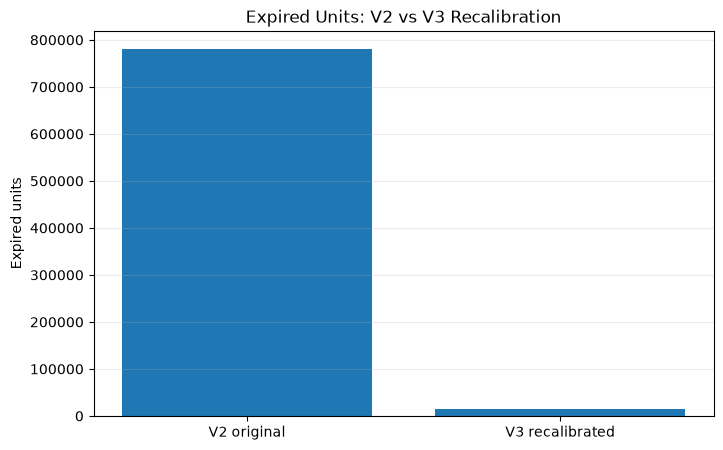

In [6]:
v2_expired = int(audit["expired_units_v2_original"].sum())
v3_expired = int(audit["expired_units"].sum())
units_reduced = v2_expired - v3_expired
reduction_pct = (units_reduced / v2_expired * 100) if v2_expired else np.nan

comparison = pd.DataFrame([
    {"metric": "Original V2 expired units", "value": v2_expired},
    {"metric": "Recalibrated V3 expired units", "value": v3_expired},
    {"metric": "Difference (V2 - V3)", "value": units_reduced},
    {"metric": "Descriptive reduction (%)", "value": reduction_pct},
])

display(comparison)

plt.figure(figsize=(8, 5))
plt.bar(["V2 original", "V3 recalibrated"], [v2_expired, v3_expired])
plt.title("Expired Units: V2 vs V3 Recalibration")
plt.ylabel("Expired units")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 7. Validate the configured expiry guardrails

The documented rule is:
- When original V2 expiry is positive, the configured allowance is `ceil(5% × latent demand)` with a minimum one-unit allowance.
- Revised expiry must not exceed available stock after fulfilled sales.
- Revised expiry must not be negative.

The audit CSV stores the resulting `expiry_cap_units` and `available_after_sales_units`; this notebook validates V3 expiry against those recorded guardrails.

In [7]:
audit["cap_violation"] = audit["expired_units"] > audit["expiry_cap_units"]
audit["available_stock_violation"] = (
    audit["expired_units"] > audit["available_after_sales_units"]
)
audit["negative_v3_expiry"] = audit["expired_units"] < 0

guardrail_summary = pd.DataFrame([
    {"guardrail": "V3 expiry exceeds recorded expiry cap",
     "violations": int(audit["cap_violation"].sum())},
    {"guardrail": "V3 expiry exceeds available stock after sales",
     "violations": int(audit["available_stock_violation"].sum())},
    {"guardrail": "V3 expiry is negative",
     "violations": int(audit["negative_v3_expiry"].sum())},
])

display(guardrail_summary)

guardrail_pass = guardrail_summary["violations"].eq(0).all()
print("Overall guardrail status:", "PASS" if guardrail_pass else "FAIL")

guardrail_exceptions = audit[
    audit["cap_violation"] |
    audit["available_stock_violation"] |
    audit["negative_v3_expiry"]
].copy()

print("Exception rows:", len(guardrail_exceptions))
display(guardrail_exceptions.head(20))

,guardrail,violations
0,V3 expiry exceeds recorded expiry cap,0
1,V3 expiry exceeds available stock after sales,0
2,V3 expiry is negative,0


Overall guardrail status: PASS
Exception rows: 0


,date,store_id,sku_id,expired_units_v2_original,expired_units,expiry_cap_units,available_after_sales_units,cap_violation,available_stock_violation,negative_v3_expiry


## 8. How many records changed?

Identify the exact date-store-SKU records where the V3 expiry differs from V2.

In [8]:
audit["units_reduced"] = (
    audit["expired_units_v2_original"] - audit["expired_units"]
)
audit["expiry_changed"] = (
    audit["expired_units_v2_original"] != audit["expired_units"]
)

change_summary = pd.DataFrame([
    {"metric": "Total audit rows", "value": len(audit)},
    {"metric": "Rows with changed expiry", "value": int(audit["expiry_changed"].sum())},
    {"metric": "Rows unchanged", "value": int((~audit["expiry_changed"]).sum())},
    {"metric": "Rows where V3 expiry is greater than V2",
     "value": int((audit["units_reduced"] < 0).sum())},
    {"metric": "Rows where V3 expiry is lower than V2",
     "value": int((audit["units_reduced"] > 0).sum())},
])

display(change_summary)

changed_records = audit.loc[audit["expiry_changed"]].sort_values(
    "units_reduced", ascending=False
)

display(changed_records.head(25))

,metric,value
0,Total audit rows,658825
1,Rows with changed expiry,28217
2,Rows unchanged,630608
3,Rows where V3 expiry is greater than V2,0
4,Rows where V3 expiry is lower than V2,28217


,date,store_id,sku_id,expired_units_v2_original,expired_units,expiry_cap_units,available_after_sales_units,cap_violation,available_stock_violation,negative_v3_expiry,units_reduced,expiry_changed
74944,2026-02-28,ST003,SKU0023,71,0,0,71,False,False,False,71,True
460701,2026-01-11,ST015,SKU0009,71,0,0,71,False,False,False,71,True
139726,2026-08-24,ST005,SKU0023,70,0,0,70,False,False,False,70,True
302279,2025-12-30,ST010,SKU0025,71,1,1,71,False,False,False,70,True
393482,2025-11-13,ST013,SKU0006,70,0,0,70,False,False,False,70,True
534032,2025-12-08,ST017,SKU0025,70,0,0,70,False,False,False,70,True
196910,2026-04-25,ST007,SKU0006,70,0,0,70,False,False,False,70,True
139766,2026-10-03,ST005,SKU0023,70,0,0,70,False,False,False,70,True
567997,2025-12-28,ST018,SKU0025,70,1,1,70,False,False,False,69,True
367588,2025-12-04,ST012,SKU0025,69,0,0,69,False,False,False,69,True


## 9. Join store and product information

In this dataset, `stores.location` is the city field. We create a clearly named `city` column for reporting without changing the source file.

The product master uses `is_perishable`.

In [9]:
store_lookup = stores[["store_id", "store_name", "location"]].drop_duplicates("store_id")
store_lookup = store_lookup.rename(columns={"location": "city"})

product_lookup = products[
    ["sku_id", "product_name", "category", "subcategory",
     "cost", "selling_price", "is_perishable", "shelf_life_days"]
].drop_duplicates("sku_id")

audit_enriched = (
    audit.merge(store_lookup, on="store_id", how="left", validate="many_to_one")
         .merge(product_lookup, on="sku_id", how="left", validate="many_to_one")
)

print("Rows after enrichment:", len(audit_enriched))
print("Missing store names:", audit_enriched["store_name"].isna().sum())
print("Missing product names:", audit_enriched["product_name"].isna().sum())

display(audit_enriched.head())

Rows after enrichment: 658825
Missing store names: 0
Missing product names: 0


,date,store_id,sku_id,expired_units_v2_original,expired_units,expiry_cap_units,available_after_sales_units,cap_violation,available_stock_violation,negative_v3_expiry,units_reduced,expiry_changed,store_name,city,product_name,category,subcategory,cost,selling_price,is_perishable,shelf_life_days
0,2025-11-01,ST001,SKU0001,0,0,1,13,False,False,False,0,False,BAN Retail 1,Bangalore,Tomato,Vegetables,Tomato,4.58,6.54,True,5
1,2025-11-02,ST001,SKU0001,0,0,1,8,False,False,False,0,False,BAN Retail 1,Bangalore,Tomato,Vegetables,Tomato,4.58,6.54,True,5
2,2025-11-03,ST001,SKU0001,0,0,1,2,False,False,False,0,False,BAN Retail 1,Bangalore,Tomato,Vegetables,Tomato,4.58,6.54,True,5
3,2025-11-04,ST001,SKU0001,0,0,1,0,False,False,False,0,False,BAN Retail 1,Bangalore,Tomato,Vegetables,Tomato,4.58,6.54,True,5
4,2025-11-05,ST001,SKU0001,0,0,1,29,False,False,False,0,False,BAN Retail 1,Bangalore,Tomato,Vegetables,Tomato,4.58,6.54,True,5


## 10. City, store, category, and SKU analysis

These tables show where the original and revised expiry quantities are concentrated. They are useful for identifying records to inspect, not for claiming operational improvements.

In [10]:
city_summary = (
    audit_enriched.groupby("city", dropna=False)
    .agg(
        v2_expired_units=("expired_units_v2_original", "sum"),
        v3_expired_units=("expired_units", "sum"),
        changed_records=("expiry_changed", "sum")
    )
    .reset_index()
)
city_summary["units_reduced"] = (
    city_summary["v2_expired_units"] - city_summary["v3_expired_units"]
)
city_summary["reduction_pct"] = np.where(
    city_summary["v2_expired_units"] > 0,
    city_summary["units_reduced"] / city_summary["v2_expired_units"] * 100,
    np.nan
)
display(city_summary.sort_values("v2_expired_units", ascending=False))

store_summary = (
    audit_enriched.groupby(["city", "store_id", "store_name"], dropna=False)
    .agg(
        v2_expired_units=("expired_units_v2_original", "sum"),
        v3_expired_units=("expired_units", "sum"),
        affected_records=("expiry_changed", "sum")
    )
    .reset_index()
)
store_summary["units_reduced"] = (
    store_summary["v2_expired_units"] - store_summary["v3_expired_units"]
)
display(store_summary.sort_values("v2_expired_units", ascending=False).head(20))

category_summary = (
    audit_enriched.groupby("category", dropna=False)
    .agg(
        v2_expired_units=("expired_units_v2_original", "sum"),
        v3_expired_units=("expired_units", "sum"),
        affected_records=("expiry_changed", "sum")
    )
    .reset_index()
)
category_summary["units_reduced"] = (
    category_summary["v2_expired_units"] - category_summary["v3_expired_units"]
)
display(category_summary.sort_values("v2_expired_units", ascending=False))

sku_summary = (
    audit_enriched.groupby(["sku_id", "product_name", "category"], dropna=False)
    .agg(
        v2_expired_units=("expired_units_v2_original", "sum"),
        v3_expired_units=("expired_units", "sum"),
        affected_records=("expiry_changed", "sum")
    )
    .reset_index()
)
sku_summary["units_reduced"] = (
    sku_summary["v2_expired_units"] - sku_summary["v3_expired_units"]
)
display(sku_summary.sort_values("v2_expired_units", ascending=False).head(20))

,city,v2_expired_units,v3_expired_units,changed_records,units_reduced,reduction_pct
0,Bangalore,306989,6303,11139,300686,97.95
1,Chennai,268338,5643,9810,262695,97.90
2,Coimbatore,204670,3843,7268,200827,98.12


,city,store_id,store_name,v2_expired_units,v3_expired_units,affected_records,units_reduced
1,Bangalore,ST002,BAN Retail 2,42938,777,1480,42161
17,Coimbatore,ST018,COI Retail 3,42011,823,1492,41188
18,Coimbatore,ST019,COI Retail 4,41964,804,1463,41160
12,Chennai,ST013,CHE Retail 5,41500,795,1489,40705
16,Coimbatore,ST017,COI Retail 2,40747,684,1449,40063
19,Coimbatore,ST020,COI Retail 5,40057,721,1440,39336
2,Bangalore,ST003,BAN Retail 3,40038,848,1445,39190
4,Bangalore,ST005,BAN Retail 5,39987,784,1416,39203
15,Coimbatore,ST016,COI Retail 1,39891,811,1424,39080
7,Bangalore,ST008,BAN Retail 8,39067,810,1423,38257


,category,v2_expired_units,v3_expired_units,affected_records,units_reduced
18,Vegetables,316560,7982,12644,308578
5,Fruits,198058,3347,6805,194711
3,Dairy,76514,1937,2808,74577
13,Ready to Eat,64009,788,1592,63221
9,Meat & Seafood,58968,589,1709,58379
2,Beverages,28224,367,745,27857
1,Bakery,20854,180,1078,20674
6,Grocery,16720,592,822,16128
4,Frozen,90,7,14,83
0,Baby Care,0,0,0,0


,sku_id,product_name,category,v2_expired_units,v3_expired_units,affected_records,units_reduced
98,SKU0099,Strawberry 200g,Fruits,54090,153,1142,53937
93,SKU0094,Dosa Batter 1kg,Ready to Eat,42020,400,855,41620
5,SKU0006,Cauliflower,Vegetables,40268,544,793,39724
24,SKU0025,Papaya,Fruits,36518,378,680,36140
97,SKU0098,Mushroom 200g,Vegetables,34895,263,896,34632
80,SKU0081,Chicken 500g,Meat & Seafood,34263,386,996,33877
22,SKU0023,Mango,Fruits,29721,328,549,29393
95,SKU0096,Tender Coconut Water,Beverages,28218,367,742,27851
8,SKU0009,Okra,Vegetables,27214,458,638,26756
81,SKU0082,Fish 500g,Meat & Seafood,24705,203,713,24502


## 11. Date-wise expiry trend

,v2_expired_units,v3_expired_units
date,,
2025-11-01,0,0
2025-11-02,0,0
2025-11-03,0,0
2025-11-04,300,15
2025-11-05,331,21


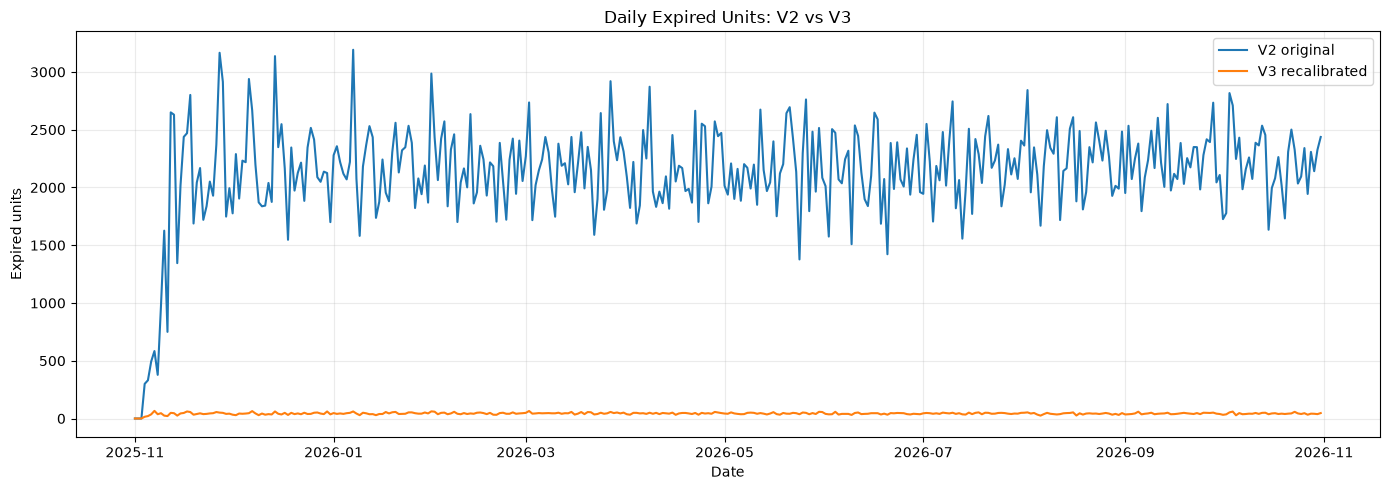

,v2_expired_units,v3_expired_units
date,,
2025-11-01,47419,1119
2025-12-01,67356,1315
2026-01-01,68793,1401
2026-02-01,60352,1248
2026-03-01,68202,1455
2026-04-01,64319,1333
2026-05-01,67006,1380
2026-06-01,63886,1246
2026-07-01,67636,1382


In [11]:
daily_summary = (
    audit.groupby("date")
    .agg(
        v2_expired_units=("expired_units_v2_original", "sum"),
        v3_expired_units=("expired_units", "sum")
    )
    .sort_index()
)

display(daily_summary.head())

plt.figure(figsize=(14, 5))
plt.plot(daily_summary.index, daily_summary["v2_expired_units"], label="V2 original")
plt.plot(daily_summary.index, daily_summary["v3_expired_units"], label="V3 recalibrated")
plt.title("Daily Expired Units: V2 vs V3")
plt.xlabel("Date")
plt.ylabel("Expired units")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

monthly_summary = daily_summary.resample("MS").sum()
display(monthly_summary)

## 12. Cross-check audit expiry against sales_daily.csv

For every date-store-SKU key, the audit's V3 `expired_units` should match the sales file's `expired_units`.

This is an important consistency check because the sales file is the operational daily record used by the rest of the project.

In [12]:
sales_expiry = sales[KEYS + ["expired_units"]].copy()
audit_expiry = audit[KEYS + ["expired_units"]].copy()

sales_expiry = sales_expiry.rename(columns={"expired_units": "sales_expired_units"})
audit_expiry = audit_expiry.rename(columns={"expired_units": "audit_expired_units"})

audit_sales_check = audit_expiry.merge(
    sales_expiry,
    on=KEYS,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

audit_sales_check["expiry_difference"] = (
    audit_sales_check["audit_expired_units"] -
    audit_sales_check["sales_expired_units"]
)

audit_sales_summary = pd.DataFrame([
    {"check": "Rows present in both audit and sales",
     "result": int((audit_sales_check["_merge"] == "both").sum())},
    {"check": "Audit-only keys",
     "result": int((audit_sales_check["_merge"] == "left_only").sum())},
    {"check": "Sales-only keys",
     "result": int((audit_sales_check["_merge"] == "right_only").sum())},
    {"check": "Expiry mismatches on matched keys",
     "result": int((
         (audit_sales_check["_merge"] == "both") &
         (audit_sales_check["expiry_difference"] != 0)
     ).sum())}
])

display(audit_sales_summary)

audit_sales_exceptions = audit_sales_check[
    (audit_sales_check["_merge"] != "both") |
    (audit_sales_check["expiry_difference"].fillna(0) != 0)
]
display(audit_sales_exceptions.head(20))

,check,result
0,Rows present in both audit and sales,658825
1,Audit-only keys,0
2,Sales-only keys,0
3,Expiry mismatches on matched keys,0


,date,store_id,sku_id,audit_expired_units,sales_expired_units,_merge,expiry_difference


## 13. Cross-check sales expiry against wastage.csv

The V3 wastage ledger should represent the expiry quantities recorded in `sales_daily.csv`.

This cell aggregates expiry wastage by date-store-SKU. It filters `wastage_type == "Expiry"` so that other wastage types, if present, are not incorrectly mixed into the comparison.

In [13]:
expiry_wastage = wastage[
    wastage["wastage_type"].astype(str).str.strip().str.lower().eq("expiry")
].copy()

wastage_by_key = (
    expiry_wastage.groupby(KEYS, as_index=False)
    .agg(wastage_expired_units=("wasted_units", "sum"))
)

sales_by_key = (
    sales.groupby(KEYS, as_index=False)
    .agg(sales_expired_units=("expired_units", "sum"))
)

sales_wastage_check = sales_by_key.merge(
    wastage_by_key,
    on=KEYS,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

sales_wastage_check["unit_difference"] = (
    sales_wastage_check["sales_expired_units"].fillna(0) -
    sales_wastage_check["wastage_expired_units"].fillna(0)
)

wastage_check_summary = pd.DataFrame([
    {"check": "Sales expiry total units",
     "result": int(sales["expired_units"].sum())},
    {"check": "Expiry wastage ledger total units",
     "result": int(expiry_wastage["wasted_units"].sum())},
    {"check": "Date-store-SKU mismatches",
     "result": int((sales_wastage_check["unit_difference"] != 0).sum())},
    {"check": "Keys only on one side",
     "result": int((sales_wastage_check["_merge"] != "both").sum())}
])

display(wastage_check_summary)

sales_wastage_exceptions = sales_wastage_check[
    (sales_wastage_check["unit_difference"] != 0) |
    (sales_wastage_check["_merge"] != "both")
]
display(sales_wastage_exceptions.head(20))

,check,result
0,Sales expiry total units,15789
1,Expiry wastage ledger total units,15789
2,Date-store-SKU mismatches,0
3,Keys only on one side,643036


,date,store_id,sku_id,sales_expired_units,wastage_expired_units,_merge,unit_difference
0,2025-11-01,ST001,SKU0001,0,NaN,left_only,0.00
1,2025-11-01,ST001,SKU0002,0,NaN,left_only,0.00
2,2025-11-01,ST001,SKU0003,0,NaN,left_only,0.00
3,2025-11-01,ST001,SKU0004,0,NaN,left_only,0.00
4,2025-11-01,ST001,SKU0005,0,NaN,left_only,0.00
5,2025-11-01,ST001,SKU0006,0,NaN,left_only,0.00
6,2025-11-01,ST001,SKU0007,0,NaN,left_only,0.00
7,2025-11-01,ST001,SKU0008,0,NaN,left_only,0.00
8,2025-11-01,ST001,SKU0009,0,NaN,left_only,0.00
9,2025-11-01,ST001,SKU0010,0,NaN,left_only,0.00


## 14. Recalculate wastage cost from the product master

Expected expiry cost is calculated as:

`wasted_units × products.cost`

This checks whether the cost stored in `wastage.csv` agrees with the product cost master. It does not establish that the cost assumption is a real market price.

,metric,value
0,Wastage ledger estimated cost,"731,724.19"
1,Recalculated cost (units × product cost),"731,724.19"
2,Absolute total cost difference,0.00
3,Rows with missing product cost,0.00
4,Rows with non-zero row-level cost difference (...,0.00


,wasted_units,recorded_cost,recalculated_cost
category,,,
Vegetables,7982,"235,815.43","235,815.43"
Fruits,3347,"199,822.58","199,822.58"
Meat & Seafood,589,"82,844.31","82,844.31"
Dairy,1937,"78,066.16","78,066.16"
Ready to Eat,788,"58,107.80","58,107.80"
Bakery,180,"38,119.20","38,119.20"
Grocery,592,"19,863.82","19,863.82"
Beverages,367,"18,038.05","18,038.05"
Frozen,7,"1,046.84","1,046.84"


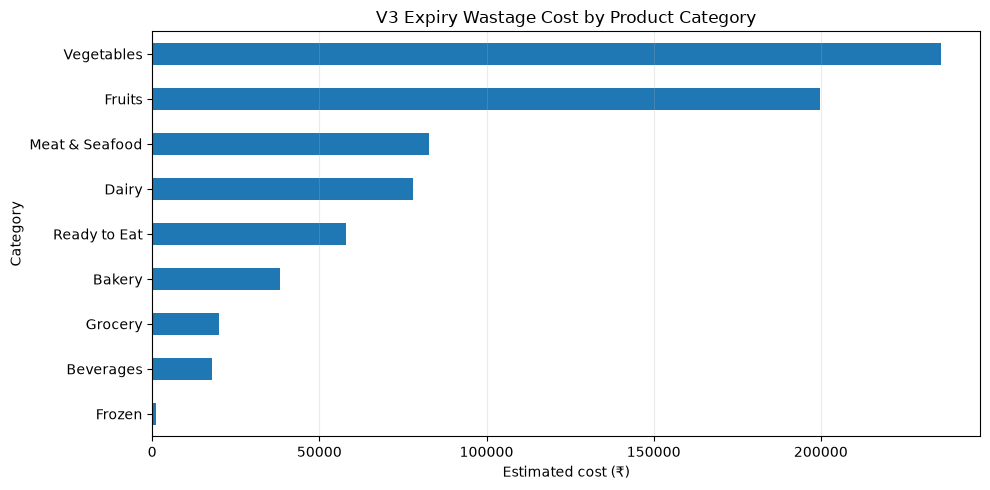

In [14]:
expiry_wastage_cost = expiry_wastage.merge(
    products[["sku_id", "product_name", "category", "cost"]],
    on="sku_id",
    how="left",
    validate="many_to_one"
)

expiry_wastage_cost["recalculated_cost"] = (
    expiry_wastage_cost["wasted_units"] * expiry_wastage_cost["cost"]
)
expiry_wastage_cost["cost_difference"] = (
    expiry_wastage_cost["estimated_cost"] -
    expiry_wastage_cost["recalculated_cost"]
)

cost_summary = pd.DataFrame([
    {"metric": "Wastage ledger estimated cost",
     "value": expiry_wastage_cost["estimated_cost"].sum()},
    {"metric": "Recalculated cost (units × product cost)",
     "value": expiry_wastage_cost["recalculated_cost"].sum()},
    {"metric": "Absolute total cost difference",
     "value": abs(expiry_wastage_cost["cost_difference"].sum())},
    {"metric": "Rows with missing product cost",
     "value": int(expiry_wastage_cost["cost"].isna().sum())},
    {"metric": "Rows with non-zero row-level cost difference (> ₹0.01)",
     "value": int((expiry_wastage_cost["cost_difference"].abs() > 0.01).sum())}
])

display(cost_summary)

category_wastage_cost = (
    expiry_wastage_cost.groupby("category", dropna=False)
    .agg(
        wasted_units=("wasted_units", "sum"),
        recorded_cost=("estimated_cost", "sum"),
        recalculated_cost=("recalculated_cost", "sum")
    )
    .sort_values("recorded_cost", ascending=False)
)
display(category_wastage_cost)

plt.figure(figsize=(10, 5))
category_wastage_cost["recorded_cost"].sort_values().plot(kind="barh")
plt.title("V3 Expiry Wastage Cost by Product Category")
plt.xlabel("Estimated cost (₹)")
plt.ylabel("Category")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 15. Stock roll-forward validation

For this V3 dataset, the daily stock equation is:

`opening_stock_units + receipts_units - quantity - expired_units = closing_stock_units`

This checks whether each sales row obeys the recorded stock movement.

In [15]:
sales["calculated_closing_stock"] = (
    sales["opening_stock_units"]
    + sales["receipts_units"]
    - sales["quantity"]
    - sales["expired_units"]
)

sales["stock_rollforward_difference"] = (
    sales["closing_stock_units"] - sales["calculated_closing_stock"]
)

stock_mismatch_count = int(
    (sales["stock_rollforward_difference"] != 0).sum()
)

stock_validation = pd.DataFrame([
    {"metric": "Sales rows", "value": len(sales)},
    {"metric": "Stock roll-forward mismatches", "value": stock_mismatch_count},
    {"metric": "Negative closing stock rows",
     "value": int((sales["closing_stock_units"] < 0).sum())},
    {"metric": "Negative expired units rows",
     "value": int((sales["expired_units"] < 0).sum())}
])

display(stock_validation)

stock_exceptions = sales[
    (sales["stock_rollforward_difference"] != 0) |
    (sales["closing_stock_units"] < 0) |
    (sales["expired_units"] < 0)
]
display(stock_exceptions.head(20))

,metric,value
0,Sales rows,658825
1,Stock roll-forward mismatches,0
2,Negative closing stock rows,0
3,Negative expired units rows,0


,date,store_id,sku_id,opening_stock_units,receipts_units,demand_units,quantity,lost_sales_units,closing_stock_units,unit_price,discount_pct,revenue,cogs,gross_profit,returns_units,channel,temperature_c,rainfall_mm,competitor_price,news_signal_present,promotion_active,expired_units,calculated_closing_stock,stock_rollforward_difference


## 16. Consolidated validation scorecard

A PASS means the corresponding structural consistency check passed on the loaded files. It does not certify that the synthetic assumptions are realistic.

In [16]:
def is_zero(value):
    return int(value) == 0

checks = [
    ("Audit key duplicates", int(audit.duplicated(KEYS).sum()) == 0,
     int(audit.duplicated(KEYS).sum())),
    ("Audit null key cells", int(audit[KEYS].isna().sum().sum()) == 0,
     int(audit[KEYS].isna().sum().sum())),
    ("Expiry cap violations", int(audit["cap_violation"].sum()) == 0,
     int(audit["cap_violation"].sum())),
    ("Available stock violations", int(audit["available_stock_violation"].sum()) == 0,
     int(audit["available_stock_violation"].sum())),
    ("Negative V3 expiry", int(audit["negative_v3_expiry"].sum()) == 0,
     int(audit["negative_v3_expiry"].sum())),
    ("Audit-sales expiry mismatches",
     int(((audit_sales_check["_merge"] == "both") &
          (audit_sales_check["expiry_difference"] != 0)).sum()) == 0,
     int(((audit_sales_check["_merge"] == "both") &
          (audit_sales_check["expiry_difference"] != 0)).sum())),
    ("Sales-wastage expiry mismatches",
     int((sales_wastage_check["unit_difference"] != 0).sum()) == 0,
     int((sales_wastage_check["unit_difference"] != 0).sum())),
    ("Stock roll-forward mismatches", stock_mismatch_count == 0,
     stock_mismatch_count),
    ("Missing product costs in expiry wastage",
     int(expiry_wastage_cost["cost"].isna().sum()) == 0,
     int(expiry_wastage_cost["cost"].isna().sum())),
    ("Wastage cost row differences over ₹0.01",
     int((expiry_wastage_cost["cost_difference"].abs() > 0.01).sum()) == 0,
     int((expiry_wastage_cost["cost_difference"].abs() > 0.01).sum())),
]

scorecard = pd.DataFrame([
    {"validation": name, "status": "PASS" if passed else "CHECK",
     "exception_count": count}
    for name, passed, count in checks
])

display(scorecard)

print(
    "Structural validation:",
    "ALL CHECKS PASSED" if (scorecard["status"] == "PASS").all()
    else "ONE OR MORE CHECKS NEED INVESTIGATION"
)

,validation,status,exception_count
0,Audit key duplicates,PASS,0
1,Audit null key cells,PASS,0
2,Expiry cap violations,PASS,0
3,Available stock violations,PASS,0
4,Negative V3 expiry,PASS,0
5,Audit-sales expiry mismatches,PASS,0
6,Sales-wastage expiry mismatches,PASS,0
7,Stock roll-forward mismatches,PASS,0
8,Missing product costs in expiry wastage,PASS,0
9,Wastage cost row differences over ₹0.01,PASS,0


Structural validation: ALL CHECKS PASSED


## 17. Export reports

The following files are written to `outputs/expiry_audit/` inside the dataset folder:
- `audit_validation_scorecard.csv`
- `city_expiry_summary.csv`
- `store_expiry_summary.csv`
- `category_expiry_summary.csv`
- `sku_expiry_summary.csv`
- `daily_expiry_summary.csv`
- `audit_sales_exceptions.csv`
- `sales_wastage_exceptions.csv`
- `stock_rollforward_exceptions.csv`
- `expiry_wastage_cost_detail.csv`
- `changed_expiry_records.csv`

These exports make it easier to inspect exceptions and reuse the findings in your project report.

In [17]:
OUTPUT_DIR = DATA_DIR / "outputs" / "expiry_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

exports = {
    "audit_validation_scorecard.csv": scorecard,
    "city_expiry_summary.csv": city_summary,
    "store_expiry_summary.csv": store_summary,
    "category_expiry_summary.csv": category_summary,
    "sku_expiry_summary.csv": sku_summary,
    "daily_expiry_summary.csv": daily_summary.reset_index(),
    "audit_sales_exceptions.csv": audit_sales_exceptions,
    "sales_wastage_exceptions.csv": sales_wastage_exceptions,
    "stock_rollforward_exceptions.csv": stock_exceptions,
    "expiry_wastage_cost_detail.csv": expiry_wastage_cost,
    "changed_expiry_records.csv": changed_records,
}

for filename, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)

print("Reports exported to:", OUTPUT_DIR)
print("Files created:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", path.name, f"({path.stat().st_size:,} bytes)")

Reports exported to: D:\TCS AI\retail_decision_intelligence_v3\outputs\expiry_audit
Files created:
- audit_sales_exceptions.csv (87 bytes)
- audit_validation_scorecard.csv (399 bytes)
- category_expiry_summary.csv (537 bytes)
- changed_expiry_records.csv (1,734,216 bytes)
- city_expiry_summary.csv (242 bytes)
- daily_expiry_summary.csv (7,321 bytes)
- expiry_wastage_cost_detail.csv (1,197,310 bytes)
- sales_wastage_exceptions.csv (27,650,635 bytes)
- sku_expiry_summary.csv (4,440 bytes)
- stock_rollforward_exceptions.csv (336 bytes)
- store_expiry_summary.csv (1,102 bytes)


## 18. Final interpretation for your project

Use the results carefully:

- **What the audit demonstrates:** V2-to-V3 expiry adjustments can be traced by date, store, and SKU; configured expiry limits can be checked; and the audit can be reconciled with sales and wastage records.
- **What it does not demonstrate:** It does not show that an AI model reduced real supermarket wastage, nor does it establish a real-world expiry rate.
- **Remaining simulation limitation:** V3 is a targeted expiry recalibration. A complete inventory simulator should model receipt lots, batch ages, FIFO/FEFO consumption, shelf-life expiry, purchase-order timing, and stock transfers consistently.

For a hackathon demo, describe this as **data quality, traceability, and simulation consistency validation**, not AI impact measurement.